# Fraud detection: from a score to a decision

This notebook trains a fraud model and turns its scores into decisions
in euros.

**The question.** A card payment comes in. Should we let it through, or
send it to a human reviewer first?

## Why this dataset

We use 284,807 real card payments made by European cardholders over two
days in September 2013. 492 of them are fraud. The data was released by
Worldline and the Machine Learning Group of ULB (Université Libre de
Bruxelles).

It fits the question for five reasons:

- **It is real.** These are actual payments, not simulated ones, so the
  rarity and messiness of fraud are real too.
- **Fraud is rare, as in practice.** Only 0.17% of payments are fraud. That
  forces us to choose metrics and decision rules carefully, because
  accuracy means nothing here.
- **It has a clock.** Every payment has a timestamp, so we can train on the
  past and test on the future instead of shuffling rows.
- **It has an amount in euros.** That lets us decide in money: a missed
  EUR 1,000 fraud and a missed EUR 1 fraud are different mistakes.
- **It is public.** Anyone can download it (Open Database License) and rerun
  this notebook on a laptop.

What it cannot do:

- The 28 bank features `V1` to `V28` are scrambled with PCA for privacy, so
  we cannot interpret them or build features by hand.
- There is no card or customer ID, so we cannot build features such as
  "payments by this card in the last hour".
- It covers only two days and holds 492 frauds, so every result carries
  wide uncertainty.

## 1. Setup

We use pandas and NumPy for tables, matplotlib for charts, scikit-learn for
the baseline and the metrics, XGBoost for the main model, and
imbalanced-learn for SMOTE.

The last three imports come from `src/` in this repository. They are
small helper functions kept in separate files because notebook 02 uses
the same ones, so both notebooks measure things the same way. The
notebook shows how each one is built where it is first used.

In [1]:
import sys
import inspect
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, precision_recall_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from src.features import FEATURES, REVIEW_COST_EUR, expected_loss
from src.features import add_hour_of_day, flag_for_review
from src.monitoring import build_reference, make_edges, share_per_bin

A few settings. The one that matters for the business is the **review
cost**: we assume it costs €5 of analyst time to check one flagged
payment. That is a round assumption, not a measured number. It lives in
`src/features.py`, so changing it there changes it in both notebooks.

In [2]:
SEED = 42
DATA_PATH = ROOT / "data" / "creditcard.csv"
ARTIFACTS = ROOT / "artifacts"
IMAGES = ROOT / "docs" / "images"

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 12)

print("Review cost per flagged payment: EUR", REVIEW_COST_EUR)

Review cost per flagged payment: EUR 5.0


## 2. Load the data

Each row is one card payment:

- `Time`: seconds since the first payment in the file.
- `V1` to `V28`: the bank's own features, scrambled with PCA for privacy.
  We cannot know what they mean, only that they carry signal.
- `Amount`: the payment in euros.
- `Class`: 1 for fraud, 0 for a normal payment.

Get the file with the instructions in `data/README.md`.

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,...,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,...,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,...,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,...,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,...,-0.206010,0.502292,0.219422,0.215153,69.99,0


284,807 payments and 31 columns, all numbers, so there is no text to parse.

## 3. First look

### 3.1 How rare is fraud?

Before any modelling we need to know how rare the thing we are hunting is.
It decides which metric makes sense.

In [4]:
counts = raw["Class"].value_counts()
summary = pd.DataFrame({"payments": counts})
summary.index = ["legit", "fraud"]
summary["share_%"] = (100 * summary["payments"] / len(raw)).round(3)
summary

,payments,share_%
legit,284315,99.827
fraud,492,0.173


Only 492 payments (0.17%) are fraud. A model that always says "legit"
would be 99.8% accurate and catch nothing, so accuracy is off the table.

### 3.2 Missing values

A quick check before we trust any column.

In [5]:
missing = raw.isna().sum()
print("Columns with missing values:", int((missing > 0).sum()))
print("Total missing cells:", int(missing.sum()))

Columns with missing values: 0
Total missing cells: 0


Nothing is missing, so there is nothing to fill in or drop here.

### 3.3 How much money is at stake?

The business loses money, not counts. So we look at amounts next, split by
fraud and legit.

In [6]:
amount_table = raw.groupby("Class")["Amount"].describe()
amount_table.index = ["legit", "fraud"]
amount_table.round(2)

,count,mean,std,min,25%,50%,75%,max
legit,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
fraud,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


The median fraud is smaller than the median legit payment, but the fraud
amounts have a long tail. Let's see how the fraud money is spread.

In [7]:
fraud_amounts = raw.loc[raw["Class"] == 1, "Amount"]
big = fraud_amounts[fraud_amounts > 500]
print("Total fraud value: EUR", round(fraud_amounts.sum()))
print("Frauds under EUR 5:", int((fraud_amounts < 5).sum()))
print("Frauds over EUR 500:", len(big))
share_big = 100 * big.sum() / fraud_amounts.sum()
print("Share of fraud value in those big ones: %.0f%%" % share_big)

Total fraud value: EUR 60128
Frauds under EUR 5: 221
Frauds over EUR 500: 35
Share of fraud value in those big ones: 52%


Fraud totals about €60,000. Almost half the frauds are under €5, but the
35 frauds over €500 carry 52% of the money: catching the big ones matters
far more than catching many.

The same story as a picture. The x-axis is on a log scale so that €1 and
€1,000 payments both fit on one chart.

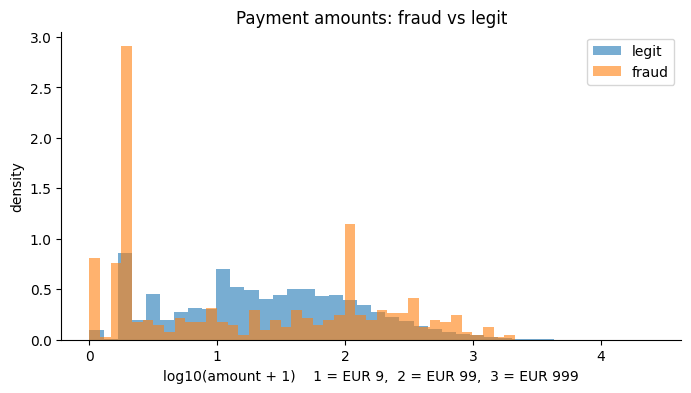

In [8]:
fig, ax = plt.subplots()
labels = {0: "legit", 1: "fraud"}
for cls in [0, 1]:
    amounts = raw.loc[raw["Class"] == cls, "Amount"]
    values = np.log10(amounts + 1)
    ax.hist(values, bins=40, density=True, alpha=0.6, label=labels[cls])
ax.set_xlabel("log10(amount + 1)    1 = EUR 9,  2 = EUR 99,  3 = EUR 999")
ax.set_ylabel("density")
ax.set_title("Payment amounts: fraud vs legit")
ax.legend()
plt.show()

Fraud clusters at both ends: many tiny amounts (card testing) and a
fatter tail of large ones.

### 3.4 Fraud over time

The file covers 48 hours. We count payments and frauds per hour to see if
the pattern changes over time. If it does, a random split would hide it.
We make a new table, `by_hour`, with one row per hour.

In [9]:
hour_number = (raw["Time"] // 3600).astype(int)
by_hour = raw.groupby(hour_number).agg(payments=("Class", "size"),
                                       frauds=("Class", "sum"))
by_hour.index.name = "hour"
by_hour["fraud_rate_%"] = 100 * by_hour["frauds"] / by_hour["payments"]
print("Shape:", by_hour.shape)
by_hour.head()

Shape: (48, 3)


,payments,frauds,fraud_rate_%
hour,,,
0,3963,2,0.050467
1,2217,2,0.090212
2,1576,21,1.332487
3,1821,13,0.713893
4,1082,6,0.554529


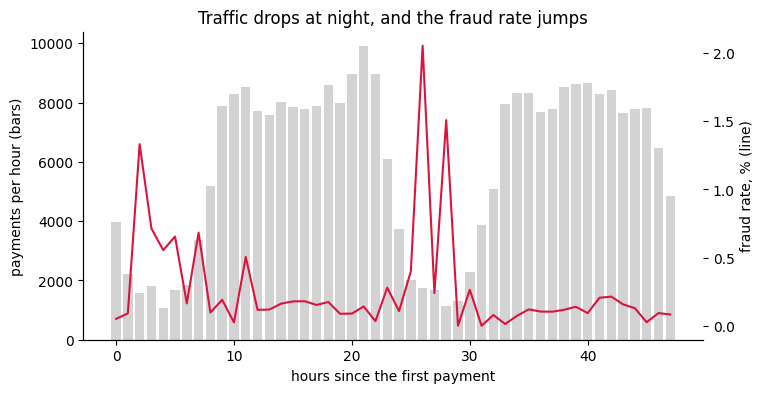

In [10]:
fig, ax1 = plt.subplots()
ax1.bar(by_hour.index, by_hour["payments"], color="lightgray")
ax1.set_xlabel("hours since the first payment")
ax1.set_ylabel("payments per hour (bars)")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["fraud_rate_%"], color="crimson")
ax2.set_ylabel("fraud rate, % (line)")
ax1.set_title("Traffic drops at night, and the fraud rate jumps")
plt.show()

Traffic falls at night (roughly hours 1 to 7 and 25 to 31), and the fraud
rate rises: some single night hours reach 1% to 2%, against roughly 0.1% to
0.2% by day. So hour of day is a useful input.

## 4. Cleaning

### 4.1 Duplicate rows

Some rows are identical in every column: the same second, the same amount
and the same 28 bank features. Two different payments matching on all 31
numbers is very unlikely, so these are almost certainly the same payment
logged twice. Keeping them would count one payment twice.

First, let's look at them.

In [11]:
dup_mask = raw.duplicated(keep="first")
dups = raw[dup_mask]
print("Duplicate rows:", len(dups))
print("Of which fraud:", int(dups["Class"].sum()))
dups[["Time", "V1", "V2", "V3", "Amount", "Class"]].head()

Duplicate rows: 1081
Of which fraud: 19


,Time,V1,V2,V3,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,6.14,0
35,26.0,-0.535388,0.865268,1.351076,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.18,0


We drop the extra copies and keep the first one of each. The result is a
new table, `clean`.

In [12]:
clean = raw.drop_duplicates(keep="first").reset_index(drop=True)
print("Before:", raw.shape)
print("After: ", clean.shape)
print("Frauds left:", int(clean["Class"].sum()))

Before: (284807, 31)
After:  (283726, 31)
Frauds left: 473


We removed 1,081 extra copies, 19 of them fraud, which leaves 473 unique
frauds.

## 5. Features

### 5.1 Hour of day instead of raw time

**Why.** `Time` only ever counts up. A model trained on it could learn
"payments late in the file are safer", and every future payment will have
a larger `Time` than anything it has seen. Hour of day repeats every day,
so it means the same thing next week.

We assume the file starts at midnight. The night-time dip in traffic in
section 3.4 lines up with that. The code is `add_hour_of_day` in
`src/features.py`, which notebook 02 also uses, so both notebooks
build the same hour. It takes a table with `Time` in
seconds and returns a copy with a new `hour_of_day` column, 0 to 23.
Here it is as written.

In [13]:
print(inspect.getsource(add_hour_of_day))


def add_hour_of_day(df):
    """Turn 'seconds since the first transaction' into an hour, 0-23."""
    df = df.copy()
    hours_elapsed = df["Time"] // SECONDS_PER_HOUR
    df["hour_of_day"] = (hours_elapsed % HOURS_PER_DAY).astype(int)
    return df



Line by line: `df.copy()` works on a copy, so the table we passed in
is not changed. `Time // 3600` counts whole hours since the first
payment. `% 24` wraps that count back to 0 after hour 23, and
`.astype(int)` keeps whole numbers. The next cell applies it and shows
five rows.

In [14]:
clean = add_hour_of_day(clean)
some_rows = [0, 60000, 120000, 180000, 240000]
clean.loc[some_rows, ["Time", "hour_of_day", "Amount", "Class"]]

,Time,hour_of_day,Amount,Class
0,0.0,0,149.62,0
60000,49231.0,13,21.99,0
120000,75839.0,21,29.95,0
180000,124650.0,10,0.89,0
240000,150796.0,17,34.33,0


Row 120,000, for example, is about 21 hours in, so it lands in hour 21.

### 5.2 Put the rows in time order

The split in the next section cuts the data by time, so the rows must be
in time order.

In [15]:
clean = clean.sort_values("Time", kind="stable").reset_index(drop=True)
print("Rows in time order?", clean["Time"].is_monotonic_increasing)
print("Shape:", clean.shape)

Rows in time order? True
Shape: (283726, 32)


### 5.3 What goes into the model, and what does not

**Kept as inputs:**

- `V1` to `V28`. Their meaning is hidden, so we cannot improve them by hand.
- `Amount`, as is. Trees do not need scaling. The logistic baseline gets
  its own scaling later.
- `hour_of_day`, from 5.1.

**Not used as inputs, with reasons:**

- `Time`: replaced by `hour_of_day` (see 5.1).
- `Class`: this is the answer we are predicting.

**What we cannot build.** The file has no card or customer ID, so
"how many payments did this card make in the last hour" is impossible
here. That is a limit of this public dataset.

We build the list in code instead of typing it out. Start from every column
in the table, skip the columns we have a reason to drop, and keep the rest.

The reasons sit in a dictionary next to the code, so each drop is written
down where it happens. Both were explained above: `Time` is replaced by
`hour_of_day`, and `Class` is the answer we are predicting.

In [16]:
DROP_REASONS = {
    "Time": "replaced by hour_of_day (section 5.1)",
    "Class": "this is the answer we are predicting",
}

feature_list = []
for col in clean.columns:
    if col in DROP_REASONS:
        continue
    feature_list.append(col)

print("Columns in the table:", len(clean.columns))
print("Dropped:", len(DROP_REASONS))
print("Kept as model inputs:", len(feature_list))

Columns in the table: 32
Dropped: 2
Kept as model inputs: 30


The dropped columns with their reasons, and the first rows of what the model
will see:

In [17]:
dropped = pd.DataFrame({"reason": DROP_REASONS})
dropped.index.name = "dropped column"
dropped

,reason
dropped column,
Time,replaced by hour_of_day (section 5.1)
Class,this is the answer we are predicting


In [18]:
print("Model inputs:", clean[feature_list].shape)
clean[feature_list].head()

Model inputs: (283726, 30)


,V1,V2,V3,V4,V5,V6,...,V25,V26,V27,V28,Amount,hour_of_day
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,...,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,...,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,...,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,...,-0.206010,0.502292,0.219422,0.215153,69.99,0


Two of the 32 columns are dropped and 30 stay: `V1` to `V28`, `Amount` and
`hour_of_day`.

Notebook 02 does not use this list directly. It imports `FEATURES` from
`src/features.py`, so both notebooks share one definition. If the two
lists ever differed, notebook 02 would feed the saved model different
columns from the ones it learned on. So we check that they are
identical, and stop the notebook if they are not.

In [19]:
lists_match = feature_list == FEATURES
print("Identical to FEATURES in src/features.py?", lists_match)
assert lists_match

Identical to FEATURES in src/features.py? True


They match: the same 30 inputs in the same order. From here on we use
`FEATURES`.

## 6. Split by time

Since fraud usually comes in bursts, there is some time dependence among fraud cases, and therefore we cannot split train test set randomly as we do for example for marketing. This similar to what is argued [here](https://fraud-detection-handbook.github.io/fraud-detection-handbook/Chapter_3_GettingStarted/BaselineModeling.html). We thus split the train-test set like the below:

- **Train**, hours 0 to 32: the model learns here.
- **Validation**, hours 32 to 40: we compare models and pick the decision
  rule here.
- **Test**, hours 40 to 48: we look at it once, at the very end.

We add a new column, `split`, that labels each row.

In [20]:
TRAIN_END_HOUR = 32
VALID_END_HOUR = 40

hours = clean["Time"] / 3600
clean["split"] = "test"
clean.loc[hours < VALID_END_HOUR, "split"] = "valid"
clean.loc[hours < TRAIN_END_HOUR, "split"] = "train"
clean[["Time", "hour_of_day", "split"]].iloc[[0, 170000, 250000]]

,Time,hour_of_day,split
0,0.0,0,train
170000,120285.0,9,valid
250000,155131.0,19,test


Now a summary of the three parts: how many payments, how many frauds, and
how much fraud money each one holds.

In [21]:
rows = []
for name in ["train", "valid", "test"]:
    part = clean[clean["split"] == name]
    fraud_part = part[part["Class"] == 1]
    start = part["Time"].min() / 3600
    end = part["Time"].max() / 3600
    rows.append({
        "split": name,
        "hours": "%.0f to %.0f" % (start, end),
        "payments": len(part),
        "frauds": len(fraud_part),
        "fraud_rate_%": round(100 * len(fraud_part) / len(part), 3),
        "fraud_value_eur": round(fraud_part["Amount"].sum()),
    })
split_table = pd.DataFrame(rows).set_index("split")
split_table

,hours,payments,frauds,fraud_rate_%,fraud_value_eur
split,,,,,
train,0 to 32,161909,338,0.209,38339
valid,32 to 40,62127,59,0.095,11857
test,40 to 48,59690,76,0.127,8395


The test period holds only 76 frauds worth €8,395, so section 12 puts
error bars on the results. The fraud rate also drops, from 0.21% in
training to about 0.1% later.

### 6.1 Why does the fraud rate differ between the parts?

The table above shows 0.209% fraud in training and about 0.1% later. Before
worrying, we check whether fraud really fell, or whether the parts simply
cover different times of day. Section 3.4 showed that fraud rises at night.
Training contains both nights (hours 0 to 7 and 24 to 31). Validation and
test (hours 32 to 48) are all daytime.

So we split each part into night (hour of day 0 to 7) and day (8 to 23) and
compare rates. The result is a new table, `rate_table`, with one row per
part and time of day. We build it without adding a column to `clean`.

In [22]:
is_night = clean["hour_of_day"] <= 7

rows = []
for name in ["train", "valid", "test"]:
    in_part = clean["split"] == name
    for label, in_band in [("night 00-07", is_night),
                           ("day 08-23", ~is_night)]:
        part = clean[in_part & in_band]
        if len(part) == 0:
            continue
        rows.append({
            "split": name,
            "time_of_day": label,
            "payments": len(part),
            "frauds": int(part["Class"].sum()),
            "fraud_rate_%": round(100 * part["Class"].mean(), 3),
        })
rate_table = pd.DataFrame(rows).set_index(["split", "time_of_day"])
rate_table

payments  frauds  fraud_rate_%
split time_of_day                                
train night 00-07     35157     147         0.418
      day 08-23      126752     191         0.151
valid day 08-23       62127      59         0.095
test  day 08-23       59690      76         0.127

Training's nights hold 0.418% fraud against 0.151% by day, nearly three
times as much. The later parts have no nights, so the fair comparison is
with training's daytime rate: 0.095% and 0.127% against 0.151%. That is a
smaller gap than the overall 0.209% suggested.

This is of course a limitation of the data, as it is very short, and only has one night-time data, but for now we cannot do anything more.

Next we pull out the model inputs `X` and the answer `y` for each part.

In [23]:
train = clean[clean["split"] == "train"]
valid = clean[clean["split"] == "valid"]
test = clean[clean["split"] == "test"]

X_train, y_train = train[FEATURES], train["Class"]
X_valid, y_valid = valid[FEATURES], valid["Class"]
X_test, y_test = test[FEATURES], test["Class"]
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_test: ", X_test.shape)

X_train: (161909, 30)
X_valid: (62127, 30)
X_test:  (59690, 30)


## 7. How we score a model

**Accuracy is useless here.** A model that says "never fraud" is right
99.8% of the time.

**PR-AUC.** Sort all payments from most to least
suspicious. Walk down the list. At each step, ask: of what I have flagged
so far, what share is really fraud (*precision*), and what share of all
fraud have I found (*recall*)? PR-AUC averages precision over the whole
walk. 1.0 is perfect. Guessing at random scores about the fraud rate,
roughly 0.001.

**Precision in the top 100.** A review team can only
check so many payments. Say it checks the 100 payments the model finds
most suspicious. Precision@100 is the share of those 100 that are really
fraud: 40 frauds among the 100 means 0.40. PR-AUC looks at the whole
list, while this looks only at the very top, where reviewers actually
work.

**A limit.** When a period holds fewer than 100 frauds, even a perfect
model cannot reach 1.0: the best possible score is the number of frauds
divided by 100. The next step prints those caps.

ROC-AUC, the more common metric, looks great (above 0.95) even for weak
models when fraud is this rare, so we do not rely on it.

**The math**, for reference: with $P_n$ and $R_n$ the precision and recall
after the $n$-th flagged payment,
$\text{PR-AUC} = \sum_n (R_n - R_{n-1})\,P_n$, and
$\text{Precision@100} = \dfrac{\text{frauds among the top 100}}{100}$.

PR-AUC and Precision@100 tell us which model *ranks* best. Section 11 turns rankings into
euros.

The function sorts payments from most to least suspicious, takes the
first 100 and returns the share that are fraud. `kind="stable"` makes
ties come out in the same order every run.

In [24]:
TOP_K = 100


def precision_at_k(y, scores, k=TOP_K):
    y = np.asarray(y)
    order = np.argsort(-np.asarray(scores), kind="stable")
    return y[order[:k]].mean()


for name, y_part in [("validation", y_valid), ("test", y_test)]:
    n_frauds = int(y_part.sum())
    cap = min(1.0, n_frauds / TOP_K)
    print("%-10s %d frauds, best possible precision@%d: %.2f"
          % (name, n_frauds, TOP_K, cap))


validation 59 frauds, best possible precision@100: 0.59
test       76 frauds, best possible precision@100: 0.76


Validation holds 59 frauds, so no model can score above 0.59 there. Test
holds 76, so its ceiling is 0.76. Read every Precision@100 below against
its ceiling, not against 1.0.

## 8. Baseline: logistic regression

A simple model tells us how much the fancy one actually adds.

Logistic regression needs inputs on similar scales, so we standardise
them. The scaler learns means and spreads **from the training part only**.
Using all the data would let information from the future leak into
training.

In [25]:
scaler = StandardScaler()
scaler.fit(X_train)

logit = LogisticRegression(max_iter=2000)
logit.fit(scaler.transform(X_train), y_train)

valid_scores = {}
valid_scores["logistic"] = logit.predict_proba(
    scaler.transform(X_valid))[:, 1]
ap = average_precision_score(y_valid, valid_scores["logistic"])
print("Logistic regression, validation PR-AUC:", round(ap, 3))

Logistic regression, validation PR-AUC: 0.643


The baseline already ranks well: 0.64, against about 0.001 for random
guessing.

## 9. Gradient-boosted trees (XGBoost)

**Intuition.** Hundreds of small decision trees, each one built to fix the
mistakes of the trees before it.

**Settings.** 400 trees of depth 4 with a small learning rate. These are
sensible defaults, not heavily tuned. Tuning hard on validation data
with only about 60 frauds would just fit that noise, so section 9.4
checks them lightly inside the training part instead.

We wrap the settings in a small function so that all three versions below
use exactly the same model.

In [26]:
def make_xgb(pos_weight=1.0, depth=4, rate=0.05, trees=400):
    return XGBClassifier(
        n_estimators=trees,
        max_depth=depth,
        learning_rate=rate,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=pos_weight,
        eval_metric="aucpr",
        random_state=SEED,
        n_jobs=2,
    )

### 9.1 Plain: learn from the data as it is

In [27]:
xgb_plain = make_xgb()
xgb_plain.fit(X_train, y_train)
valid_scores["xgb_plain"] = xgb_plain.predict_proba(X_valid)[:, 1]
ap = average_precision_score(y_valid, valid_scores["xgb_plain"])
print("XGBoost (plain), validation PR-AUC:", round(ap, 3))

XGBoost (plain), validation PR-AUC: 0.78


XGBoost lifts validation PR-AUC from 0.64 to 0.78.

### 9.2 Class weights: make each fraud count more

A common fix for rare classes. Each training fraud counts as much as
(number of legit payments ÷ number of frauds) legit payments. We compute
that ratio on the training part only.

In [28]:
n_legit = int((y_train == 0).sum())
n_fraud = int((y_train == 1).sum())
pos_weight = n_legit / n_fraud
print("Each training fraud counts as", round(pos_weight), "payments")

xgb_weighted = make_xgb(pos_weight)
xgb_weighted.fit(X_train, y_train)
valid_scores["xgb_weighted"] = xgb_weighted.predict_proba(X_valid)[:, 1]
ap = average_precision_score(y_valid, valid_scores["xgb_weighted"])
print("XGBoost (class weights), validation PR-AUC:", round(ap, 3))

Each training fraud counts as 478 payments


XGBoost (class weights), validation PR-AUC: 0.755


### 9.3 SMOTE: invent extra frauds

SMOTE creates new fraud rows by drawing points between existing frauds,
until both classes are the same size.

We apply it to the **training part only**. Validation and test stay 100%
real, because grading a model on invented payments tells us nothing.
The table shows the training labels before and after.

In [29]:
smote = SMOTE(random_state=SEED)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
smote_counts = pd.DataFrame({
    "before": y_train.value_counts(),
    "after_smote": y_smote.value_counts(),
})
smote_counts.index = ["legit", "fraud"]
smote_counts

,before,after_smote
legit,161571,161571
fraud,338,161571


In [30]:
xgb_smote = make_xgb()
xgb_smote.fit(X_smote, y_smote)
valid_scores["xgb_smote"] = xgb_smote.predict_proba(X_valid)[:, 1]
ap = average_precision_score(y_valid, valid_scores["xgb_smote"])
print("XGBoost (SMOTE), validation PR-AUC:", round(ap, 3))

XGBoost (SMOTE), validation PR-AUC: 0.742


### 9.4 Does tuning help? A light check

Section 9 used sensible defaults. Would other settings do better? We
check, but not on the validation part. It holds only 59 frauds, and we
still need it untouched to choose the decision rule in section 11.
Instead we test settings **inside the training part**, in time order:
train on the earlier hours, score the next few hours, three times.
This is the same walk-forward idea as our main split, so nothing from
the future leaks into a check. Each setting gets the average PR-AUC of
its three checks.

**The rule, written before we look:** we switch away from the defaults
only if the best setting beats them by more than the spread between
folds. A smaller gain is as likely to be luck as skill.

First the three folds, as a table: hours to train on, hours to score,
and how many frauds the scored hours hold.

In [31]:
FOLD_EDGES = [(14, 20), (20, 26), (26, 32)]
train_hours = train["Time"] / 3600

folds = []
rows = []
for start, end in FOLD_EDGES:
    fit_rows = train[train_hours < start]
    in_check = (train_hours >= start) & (train_hours < end)
    check_rows = train[in_check]
    folds.append((fit_rows, check_rows))
    rows.append({
        "train_hours": "0 to %d" % start,
        "train_payments": len(fit_rows),
        "score_hours": "%d to %d" % (start, end),
        "score_payments": len(check_rows),
        "score_frauds": int(check_rows["Class"].sum()),
    })
fold_table = pd.DataFrame(rows)
fold_table.index = [1, 2, 3]
fold_table


,train_hours,train_payments,score_hours,score_payments,score_frauds
1,0 to 14,62461,14 to 20,47956,70
2,0 to 20,110417,20 to 26,39530,50
3,0 to 26,149947,26 to 32,11962,54


The first fold scores daytime only, the second a mix, and the third
the second night. Each holds 50 to 70 frauds, and the folds differ in
size, so we look at all three, not only the average.

Now a small function that trains one setting on every fold and returns
the three PR-AUC scores.

In [32]:
def fold_pr_aucs(depth, rate, trees):
    scores = []
    for fit_rows, check_rows in folds:
        model = make_xgb(1.0, depth, rate, trees)
        model.fit(fit_rows[FEATURES], fit_rows["Class"])
        probs = model.predict_proba(check_rows[FEATURES])[:, 1]
        scores.append(average_precision_score(check_rows["Class"],
                                              probs))
    return np.array(scores)


The search: 3 depths x 2 learning rates x 2 tree counts is 12 settings.
Our defaults (depth 4, rate 0.05, 400 trees) are one of them. For each
setting we keep the average, the spread between folds (standard
deviation) and the worst fold.

In [33]:
tune_rows = []
for depth in [3, 4, 6]:
    for rate in [0.05, 0.1]:
        for trees in [200, 400]:
            s = fold_pr_aucs(depth, rate, trees)
            tune_rows.append({
                "depth": depth, "rate": rate, "trees": trees,
                "mean_pr_auc": s.mean(),
                "fold_spread": s.std(ddof=1),
                "worst_fold": s.min(),
            })
tune_table = pd.DataFrame(tune_rows)
tune_table = tune_table.sort_values("mean_pr_auc", ascending=False)
tune_table.round(3).reset_index(drop=True)


,depth,rate,trees,mean_pr_auc,fold_spread,worst_fold
0,3,0.05,400,0.811,0.082,0.723
1,3,0.10,400,0.805,0.089,0.709
2,4,0.05,400,0.802,0.080,0.716
3,3,0.05,200,0.799,0.081,0.708
4,3,0.10,200,0.798,0.091,0.699
5,6,0.05,400,0.798,0.089,0.700
6,4,0.10,400,0.797,0.096,0.691
7,4,0.10,200,0.796,0.092,0.696
8,4,0.05,200,0.796,0.072,0.715
9,6,0.05,200,0.795,0.093,0.691


All 12 settings land between 0.783 and 0.811, a range of about 0.03.
The folds differ from each other by about 0.08, so the settings are
not separable. The best one (depth 3, rate 0.05, 400 trees) beats our
defaults by 0.009 (0.811 against 0.802), far less than the spread. By
the rule we wrote down, **we keep the defaults**.

One pattern is worth a note: in each of the four rate and tree-count
combinations, depth 3 scores slightly ahead of depth 4, which scores
ahead of depth 6. That hints that shallow trees are enough, but the
gaps are tiny next to the spread, and 50 to 70 frauds per fold cannot
settle it. Tuning is a tried and honest dead end here: the model is
not sensitive to these settings.

## 10. Compare the models on validation

We can compare the performance of models comes in two ways:

1. **Ranking:** PR-AUC, and precision in the top 100. Ranking is more important if we want to review the cases and we have limited capacity to review them.
2. **Honest probabilities:** does the average predicted fraud probability
   match the actual fraud rate? The probabilities are important if we have a live system, like credit card transaction system, that needs to judge in real time whether to flag the transaction or not. We need honest probabilities in section 11,
   where we multiply them by euros.

In [34]:
rows = []
for name in valid_scores:
    scores = valid_scores[name]
    rows.append({
        "model": name,
        "pr_auc": round(average_precision_score(y_valid, scores), 3),
        "precision_at_100": round(precision_at_k(y_valid, scores), 3),
        "avg_predicted_%": round(100 * scores.mean(), 3),
        "actual_fraud_%": round(100 * y_valid.mean(), 3),
    })
valid_table = pd.DataFrame(rows).set_index("model")
valid_table

,pr_auc,precision_at_100,avg_predicted_%,actual_fraud_%
model,,,,
logistic,0.643,0.45,0.151,0.095
xgb_plain,0.780,0.47,0.105,0.095
xgb_weighted,0.755,0.46,0.218,0.095
xgb_smote,0.742,0.46,0.849,0.095


The plain model ranks best, and its average prediction (0.105%) is close
to the real fraud rate (0.095%). Class weights double the predicted rate
and SMOTE inflates it about nine times, and neither ranks any better.

In its top 100 the plain model holds 47 of the 59 validation frauds
(precision 0.47, ceiling 0.59). Logistic regression gets 45 and the
other two 46: a gap of one or two frauds, too small to rank the models.
PR-AUC separates them more clearly.

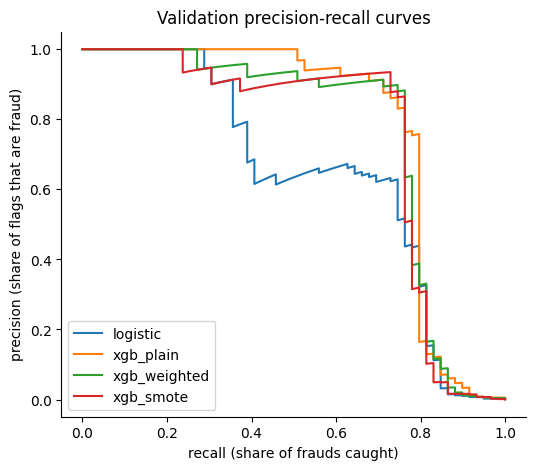

In [35]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in valid_scores:
    precision, recall, _ = precision_recall_curve(y_valid,
                                                  valid_scores[name])
    ax.plot(recall, precision, label=name)
ax.set_xlabel("recall (share of frauds caught)")
ax.set_ylabel("precision (share of flags that are fraud)")
ax.set_title("Validation precision-recall curves")
ax.legend()
IMAGES.mkdir(parents=True, exist_ok=True)
fig.savefig(IMAGES / "pr_curves.png", dpi=120, bbox_inches="tight")
plt.show()

The three XGBoost curves sit close together, all well above the logistic
baseline. Resampling changes the scores but does not improves the
ranking. **We choose the plain model.**

### 10.1 Can we trust the plain model's probabilities?

We group validation payments by predicted probability and compare the
average prediction with the real fraud share in each group. If the two
columns match, the scores behave like real probabilities.

In [36]:
buckets = [0, 0.001, 0.01, 0.1, 0.5, 0.9, 1.0]
calib = pd.DataFrame({"prob": valid_scores["xgb_plain"],
                      "fraud": y_valid.values})
calib["bucket"] = pd.cut(calib["prob"], buckets, include_lowest=True)
calib_table = calib.groupby("bucket", observed=True).agg(
    payments=("fraud", "size"),
    avg_predicted=("prob", "mean"),
    actual_rate=("fraud", "mean"),
)
calib_table.round(4)

,payments,avg_predicted,actual_rate
bucket,,,
"(-0.001, 0.001]",61011,0.0001,0.0001
"(0.001, 0.01]",940,0.0025,0.0064
"(0.01, 0.1]",92,0.0257,0.0000
"(0.1, 0.5]",29,0.2682,0.0690
"(0.5, 0.9]",16,0.7272,0.5625
"(0.9, 1.0]",39,0.9807,0.9231


Very low and very high probabilities are about right. Between 1% and 50%
the model is overconfident, but only about 110 of 62,000 payments land
there. That is good enough to multiply by euros, with this caveat noted.

## 11. From a score to a decision

**The intuition.** Reviewing a payment costs €5. Letting a fraud through
costs its full amount. So for every payment we ask one question: *is the
money we expect to lose bigger than the €5 a review costs?*

- A 2% fraud chance on €1,000 means €20 of expected loss. Review it.
- A 60% fraud chance on €3 means €1.80. Let it through: the review costs
  more than the fraud could.

**The math.** With fraud probability $p$, amount $a$ and review cost $c$:
review when $p \times a > c$.

**How we score a rule.** Its total cost on a set of payments:

$$\text{cost} = c \times (\text{number flagged})
+ \sum \text{amounts of frauds we did not flag}$$

We write that as a function.

In [37]:
def total_cost(y, amount, flagged, review_cost=REVIEW_COST_EUR):
    y = np.asarray(y)
    amount = np.asarray(amount)
    flagged = np.asarray(flagged)
    review_bill = review_cost * flagged.sum()
    missed = (y == 1) & (~flagged)
    missed_fraud = amount[missed].sum()
    return review_bill + missed_fraud

We compare three rules, all using the plain model's probabilities:

- **Threshold 0.5**: flag when $p \ge 0.5$. Most natural default.
- **Best single threshold**: the one cutoff that is cheapest on
  validation.
- **Amount-aware**: flag when expected loss is greater than review cost: $p \times a > 5$.

We also include **no model**, approving everything, as the floor.

### 11.1 The best single threshold, picked on validation

In [38]:
p_valid = valid_scores["xgb_plain"]
amount_valid = valid["Amount"].values
thresholds = np.linspace(0.01, 0.99, 99)
valid_costs = []
for t in thresholds:
    flagged = p_valid >= t
    valid_costs.append(total_cost(y_valid, amount_valid, flagged))

best_i = int(np.argmin(valid_costs))
best_threshold = float(thresholds[best_i])
print("Cheapest single threshold on validation:", round(best_threshold, 2))
print("Validation cost there: EUR", round(valid_costs[best_i]))

Cheapest single threshold on validation: 0.74
Validation cost there: EUR 4731


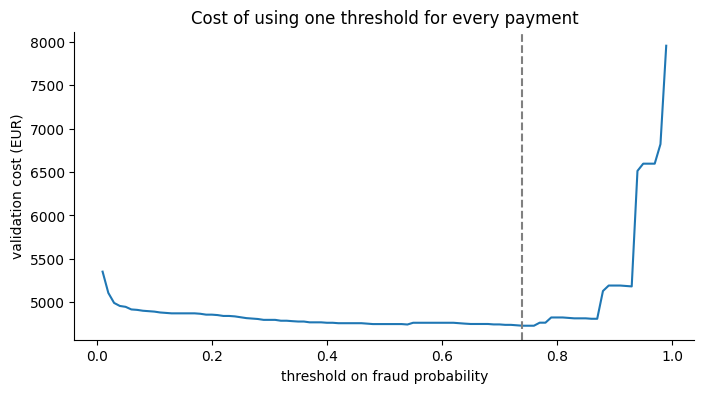

In [39]:
fig, ax = plt.subplots()
ax.plot(thresholds, valid_costs)
ax.axvline(best_threshold, color="gray", linestyle="--")
ax.set_xlabel("threshold on fraud probability")
ax.set_ylabel("validation cost (EUR)")
ax.set_title("Cost of using one threshold for every payment")
plt.show()

The curve is almost flat from 0.1 to 0.85: any sensible single threshold
costs about the same, in particular 0.5 threshold.

**The amount-aware rule, as code.** It is two small functions in
`src/features.py`, the file notebook 02 also uses, so both notebooks
apply exactly this rule. `expected_loss` multiplies the fraud
probability by the amount. `flag_for_review` asks whether that
expected loss is bigger than the review cost and answers True (send to
review) or False (approve). It works on one payment or on a whole
array. Here they are as written.

In [40]:
print(inspect.getsource(expected_loss))
print(inspect.getsource(flag_for_review))


def expected_loss(fraud_prob, amount):
    """Money we expect to lose if we let the transaction through."""
    return fraud_prob * amount

def flag_for_review(fraud_prob, amount, review_cost=REVIEW_COST_EUR):
    """Review when the expected loss is bigger than the cost of a review.

    Works on single numbers and on whole arrays.
    """
    return np.asarray(expected_loss(fraud_prob, amount)) > review_cost



Now the rule on the two examples from the start of this section, plus
one in between: a 30% chance on €40.

In [41]:
demo = pd.DataFrame({"fraud_prob": [0.02, 0.60, 0.30],
                     "amount": [1000.0, 3.0, 40.0]})
demo["expected_loss"] = expected_loss(demo["fraud_prob"],
                                      demo["amount"])
demo["review"] = flag_for_review(demo["fraud_prob"], demo["amount"])
demo


,fraud_prob,amount,expected_loss,review
0,0.02,1000.0,20.0,True
1,0.60,3.0,1.8,False
2,0.30,40.0,12.0,True


€20 of expected loss is more than the €5 review cost, so the first
payment is reviewed. €1.80 is less, so the 60% case on €3 is approved.
The 30% chance on €40 is €12 of expected loss, so it is reviewed: a
middling probability still gets a review once enough money is at stake.

### 11.2 All rules on validation

In [42]:
label_best = "threshold %.2f" % best_threshold
rules_valid = {
    "no model (approve all)": np.zeros(len(valid), dtype=bool),
    "threshold 0.5": p_valid >= 0.5,
    label_best: p_valid >= best_threshold,
    "amount-aware": flag_for_review(p_valid, amount_valid),
}
rows = []
for name in rules_valid:
    flagged = rules_valid[name]
    cost = total_cost(y_valid, amount_valid, flagged)
    rows.append({"rule": name, "flagged": int(flagged.sum()),
                 "cost_eur": round(cost)})
pd.DataFrame(rows).set_index("rule")

,flagged,cost_eur
rule,,
no model (approve all),0,11857
threshold 0.5,55,4750
threshold 0.74,46,4731
amount-aware,88,4931


On validation the three rules are close, within about €200 of each
other, and all cut the cost of approving everything by about 60%. Note
that the amount-aware rule was not tuned here at all: its only setting is
the €5 review cost.

## 12. The final exam: the test period

Everything so far was decided without looking at hours 40 to 48. Now we
look, once.

### 12.1 Ranking, for the record

In [43]:
test_scores = {}
test_scores["logistic"] = logit.predict_proba(
    scaler.transform(X_test))[:, 1]
test_scores["xgb_plain"] = xgb_plain.predict_proba(X_test)[:, 1]
test_scores["xgb_weighted"] = xgb_weighted.predict_proba(X_test)[:, 1]
test_scores["xgb_smote"] = xgb_smote.predict_proba(X_test)[:, 1]

rows = []
for name in test_scores:
    ap = average_precision_score(y_test, test_scores[name])
    p100 = precision_at_k(y_test, test_scores[name])
    rows.append({"model": name, "test_pr_auc": round(ap, 3),
                 "test_precision_at_100": round(p100, 3)})
pd.DataFrame(rows).set_index("model")

,test_pr_auc,test_precision_at_100
model,,
logistic,0.706,0.57
xgb_plain,0.797,0.60
xgb_weighted,0.790,0.59
xgb_smote,0.797,0.59


The ranking holds on the future: plain XGBoost scores 0.80 (tied with
SMOTE this time), well above the logistic baseline. Resampling still
does not beat doing nothing.

In its top 100, plain XGBoost holds 60 of the 76 test frauds (0.60,
ceiling 0.76), against 57 for logistic regression and 59 for class
weights and SMOTE. The gaps between models
are again only a few frauds.

Section 6.1 looked at the drop in fraud rate, so one more check: does the
model's average predicted fraud rate still match the actual rate on the test
period?

In [44]:
avg_predicted = 100 * test_scores["xgb_plain"].mean()
actual_rate = 100 * y_test.mean()
print("Average predicted fraud rate: %.3f%%" % avg_predicted)
print("Actual fraud rate:            %.3f%%" % actual_rate)

Average predicted fraud rate: 0.128%
Actual fraud rate:            0.127%


They match. The lower fraud rate on the test period
did not throw off the model's probabilities.

### 12.2 The decision rules, in euros

We apply the rules chosen on validation to the test period.

In [45]:
p_test = test_scores["xgb_plain"]
amount_test = test["Amount"].values
y_test_arr = y_test.values
rules_test = {
    "no model (approve all)": np.zeros(len(test), dtype=bool),
    "threshold 0.5": p_test >= 0.5,
    label_best + " (from validation)": p_test >= best_threshold,
    "amount-aware": flag_for_review(p_test, amount_test),
}
print("Rules to compare:", list(rules_test))

Rules to compare: ['no model (approve all)', 'threshold 0.5', 'threshold 0.74 (from validation)', 'amount-aware']


In [46]:
rows = []
for name in rules_test:
    flagged = rules_test[name]
    caught = flagged & (y_test_arr == 1)
    cost = total_cost(y_test_arr, amount_test, flagged)
    rows.append({
        "rule": name,
        "flagged": int(flagged.sum()),
        "frauds_caught": int(caught.sum()),
        "fraud_eur_caught": round(amount_test[caught].sum()),
        "total_cost_eur": round(cost),
    })
test_table = pd.DataFrame(rows).set_index("rule")
test_table

,flagged,frauds_caught,fraud_eur_caught,total_cost_eur
rule,,,,
no model (approve all),0,0,0,8395
threshold 0.5,67,58,4724,4006
threshold 0.74 (from validation),59,56,4717,3973
amount-aware,73,25,5954,2807


The amount-aware rule is cheapest: €2,807 against €4,006 for the 0.5
threshold. It catches fewer frauds (25 against 58) but more fraud money
(€5,954 against €4,724), because it spends reviews on large payments and
lets through tiny frauds that cost less than a review.

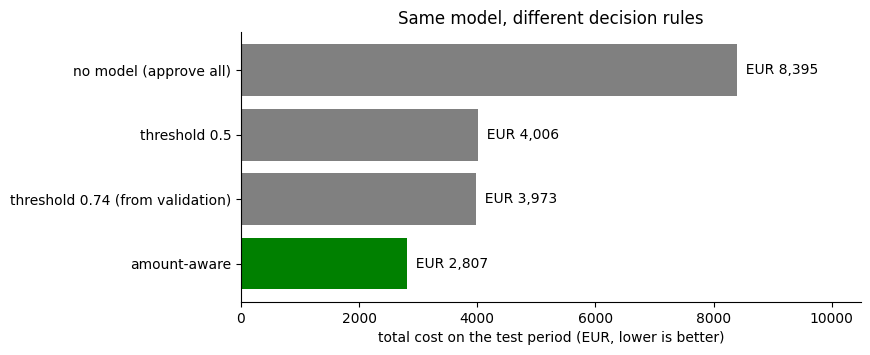

In [47]:
fig, ax = plt.subplots(figsize=(8, 3.5))
names = list(test_table.index)
costs = test_table["total_cost_eur"].values
colors = []
for name in names:
    colors.append("green" if name == "amount-aware" else "gray")
ax.barh(names, costs, color=colors)
for i in range(len(names)):
    ax.text(costs[i], i, "  EUR %s" % format(costs[i], ","), va="center")
ax.invert_yaxis()
ax.set_xlabel("total cost on the test period (EUR, lower is better)")
ax.set_title("Same model, different decision rules")
ax.set_xlim(0, costs.max() * 1.25)
fig.savefig(IMAGES / "cost_by_rule.png", dpi=120, bbox_inches="tight")
plt.show()

### 12.3 How sure can we be?

The test period has fewer than 80 frauds, so a few large ones can swing
the totals. To see how much, we re-deal the test period 1,000 times:
draw its payments at random with replacement, and recompute the saving
each time. This is the bootstrap.

In [48]:
rng = np.random.default_rng(SEED)
flag_05 = rules_test["threshold 0.5"]
flag_aa = rules_test["amount-aware"]
flag_none = rules_test["no model (approve all)"]
vs_05 = []
vs_none = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    y_b, a_b = y_test_arr[idx], amount_test[idx]
    cost_aa = total_cost(y_b, a_b, flag_aa[idx])
    vs_05.append(total_cost(y_b, a_b, flag_05[idx]) - cost_aa)
    vs_none.append(total_cost(y_b, a_b, flag_none[idx]) - cost_aa)

for label, s in [("no model", vs_none), ("threshold 0.5", vs_05)]:
    low, mid, high = np.percentile(s, [2.5, 50, 97.5])
    share = np.mean(np.array(s) > 0)
    print("Saving vs %-14s EUR %5.0f  (95%%: %5.0f to %5.0f), "
          "cheaper in %.0f%% of re-deals" % (label, mid, low, high,
                                             100 * share))

Saving vs no model       EUR  5482  (95%:  1995 to  9848), cheaper in 100% of re-deals
Saving vs threshold 0.5  EUR  1032  (95%:   -63 to  3707), cheaper in 92% of re-deals


Against approving everything, the model saves money in every re-deal.
Against threshold 0.5, the amount-aware rule is cheaper in 92% of
re-deals, but the 95% interval touches zero, and on validation the two were
nearly tied. A fair summary: it is at least as good, needs no tuning, and
pulls ahead when large frauds show up.

### 12.4 The problem with SMOTE probabilities

What if we had trained with SMOTE and then used the amount-aware rule? The
rule multiplies the model's probability by the amount, so it only works if
the probabilities are honest.

In [49]:
smote_flags = flag_for_review(test_scores["xgb_smote"], amount_test)
smote_cost = total_cost(y_test_arr, amount_test, smote_flags)
no_model_cost = test_table.loc["no model (approve all)", "total_cost_eur"]
print("SMOTE model + amount-aware rule")
print("  payments flagged:", int(smote_flags.sum()))
print("  total cost:      EUR", round(smote_cost))
print("Approving everything costs EUR", no_model_cost)

SMOTE model + amount-aware rule
  payments flagged: 1462
  total cost:      EUR 8918
Approving everything costs EUR 8395


The SMOTE model's inflated probabilities flag lots of payments, and the
review bill makes this worse than having no model at all. If you train
with SMOTE, its scores are not probabilities.

### 12.5 Which frauds get through?

We split the test frauds into caught and missed and compare their amounts.

In [50]:
is_fraud = y_test_arr == 1
caught_rows = test[is_fraud & flag_aa]
missed_rows = test[is_fraud & ~flag_aa]
compare = pd.DataFrame({
    "caught": caught_rows["Amount"].describe(),
    "missed": missed_rows["Amount"].describe(),
})
compare.round(2)

,caught,missed
count,25.00,51.00
mean,238.14,47.88
std,348.77,181.93
min,6.74,0.00
25%,45.51,0.77
50%,94.82,1.00
75%,247.86,4.80
max,1504.93,1096.99


The missed frauds are mostly tiny: half are €1 or less and three quarters
are under €5, so reviewing them would cost more than they are worth. The
largest miss, €1,097, is the case worth studying next.

### 12.6 What a random split would have shown

Section 6 explains why we split by time. Here we measure how much that
choice matters. We cut the data three ways, with the same part sizes as our
time split, and train and score the same model each time:

- **Time split**: ours.
- **Shuffled split**: rows in random order. We repeat it with 8 seeds.
- **Stratified split**: shuffled, but every part keeps the same fraud share.
  Also 8 seeds.

We report PR-AUC, precision in the top 100 and ROC-AUC on the test part.
The first two rise when the test part simply holds more fraud, so we also
show the fraud share of each test part. ROC-AUC does not depend on that share, which makes it the fairer
comparison here.

In [51]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split


def score_split(train_rows, test_rows):
    model = make_xgb()
    model.fit(train_rows[FEATURES], train_rows["Class"])
    probs = model.predict_proba(test_rows[FEATURES])[:, 1]
    return {
        "pr_auc": average_precision_score(test_rows["Class"], probs),
        "precision_at_100": precision_at_k(test_rows["Class"], probs),
        "roc_auc": roc_auc_score(test_rows["Class"], probs),
        "test_fraud_%": 100 * test_rows["Class"].mean(),
    }

Two functions that cut the table into a training part and a test part of the
same sizes as ours, one shuffled and one stratified. Stratified means the
fraud share is the same in every part.

In [52]:
n_train = len(train)
n_test = len(test)
labels = clean["Class"].values
all_rows = np.arange(len(clean))


def shuffled_parts(seed):
    order = np.random.default_rng(seed).permutation(len(clean))
    return clean.iloc[order[:n_train]], clean.iloc[order[-n_test:]]


def stratified_parts(seed):
    rest, test_idx = train_test_split(
        all_rows, test_size=n_test, stratify=labels, random_state=seed)
    train_idx, _ = train_test_split(
        rest, train_size=n_train, stratify=labels[rest], random_state=seed)
    return clean.iloc[train_idx], clean.iloc[test_idx]

Now the runs: one for our time split, then 8 seeds for each of the other
two. Each row of `all_scores` is one trained model.

In [53]:
time_scores = score_split(train, test)
time_scores["split"] = "time (ours)"
rows = [time_scores]

for seed in range(8):
    for name, cutter in [("shuffled", shuffled_parts),
                         ("stratified", stratified_parts)]:
        train_part, test_part = cutter(seed)
        scores = score_split(train_part, test_part)
        scores["split"] = name
        rows.append(scores)

all_scores = pd.DataFrame(rows)
print("Shape:", all_scores.shape)
all_scores.round(3)

Shape: (17, 5)


,pr_auc,precision_at_100,roc_auc,test_fraud_%,split
0,0.797,0.60,0.983,0.127,time (ours)
1,0.848,0.77,0.982,0.152,shuffled
2,0.875,0.86,0.985,0.168,stratified
3,0.880,0.91,0.984,0.176,shuffled
4,0.781,0.77,0.965,0.168,stratified
5,0.857,0.78,0.990,0.156,shuffled
6,0.830,0.80,0.975,0.168,stratified
7,0.775,0.68,0.986,0.134,shuffled
8,0.798,0.79,0.986,0.168,stratified
9,0.849,0.83,0.979,0.168,shuffled


In [54]:
summary = all_scores.groupby("split").agg(
    runs=("pr_auc", "size"),
    pr_auc_mean=("pr_auc", "mean"),
    pr_auc_std=("pr_auc", "std"),
    precision_at_100_mean=("precision_at_100", "mean"),
    roc_auc_mean=("roc_auc", "mean"),
    test_fraud_pct=("test_fraud_%", "mean"),
)
summary.round(3)

,runs,pr_auc_mean,pr_auc_std,precision_at_100_mean,roc_auc_mean,test_fraud_pct
split,,,,,,
shuffled,8,0.844,0.038,0.810,0.983,0.162
stratified,8,0.829,0.033,0.815,0.982,0.168
time (ours),1,0.797,NaN,0.600,0.983,0.127


ROC-AUC is the same for all three splits (0.98). PR-AUC is higher for the
shuffled and stratified splits (0.84 and 0.83, against 0.80 for ours), but
their test parts hold more fraud (about 0.16% against 0.13%), which lifts
PR-AUC by itself. The seed-to-seed spread (0.03 to 0.04) is as large as the
gap. So on this dataset the choice of split moves the headline number less
than the luck of the draw does. Our time split is one draw, so its 0.80
carries noise too.

Precision@100 shows the same pattern: 0.81 and 0.82 for the shuffled and
stratified splits, against 0.60 for ours. Their ceiling is higher too,
because their test parts hold about a quarter more fraud, so more
frauds fit into the top 100. As a rough check, scaling our 0.60 by that
extra fraud gives 0.77 to 0.79, close to what they score.

### 12.7 Why a shuffled split can still flatter the model

The averages hide a mechanism. Fraud often arrives in bursts, such as one
stolen card tried several times within minutes. Shuffle the rows and those
near-copies land on both sides of the split, so the model gets a hint of the
very frauds it is tested on.

To see it, we take every fraud in a test part and measure how far its
nearest training fraud is, using the 28 bank features standardised with the
training part's mean and spread. A distance below 1 means a near-copy.

In [55]:
v_cols = []
for i in range(1, 29):
    v_cols.append("V" + str(i))
mean_v = train[v_cols].mean()
std_v = train[v_cols].std()


def nearest_fraud_distance(train_rows, test_rows):
    a = (train_rows[train_rows["Class"] == 1][v_cols] - mean_v) / std_v
    b = (test_rows[test_rows["Class"] == 1][v_cols] - mean_v) / std_v
    distances = []
    for row in b.values:
        gap = a.values - row
        distances.append(np.sqrt((gap ** 2).sum(axis=1)).min())
    return np.array(distances)

In [56]:
d_time = nearest_fraud_distance(train, test)
shuffled_train, shuffled_test = shuffled_parts(0)
d_shuffled = nearest_fraud_distance(shuffled_train, shuffled_test)

near_table = pd.DataFrame({
    "test_frauds": [len(d_time), len(d_shuffled)],
    "median_distance": [np.median(d_time), np.median(d_shuffled)],
    "share_below_1_%": [100 * np.mean(d_time < 1),
                        100 * np.mean(d_shuffled < 1)],
}, index=["time split", "shuffled split (seed 0)"])
near_table.round(2)

,test_frauds,median_distance,share_below_1_%
time split,76,5.48,0.00
shuffled split (seed 0),91,3.95,7.69


With our time split no test fraud has a near-copy in training. With the
shuffled split (seed 0), 7.7% of test frauds do, and the typical test fraud
sits closer to a training fraud (median 3.95 against 5.48). The leak is
small but real, and a time split removes it. Cutting at distance 1 is a
judgment call; the median distances tell the same story without a cutoff.

Therefore we see that shuffled split may increase the performance of the model, but it is probably because due to leakage, and theoretically not sound.

## 13. What the model pays attention to

Feature importance by *gain*: how much each input improved the trees'
splits in total. The `V` columns are anonymous, so we can say *which*
inputs matter, but not *why*.

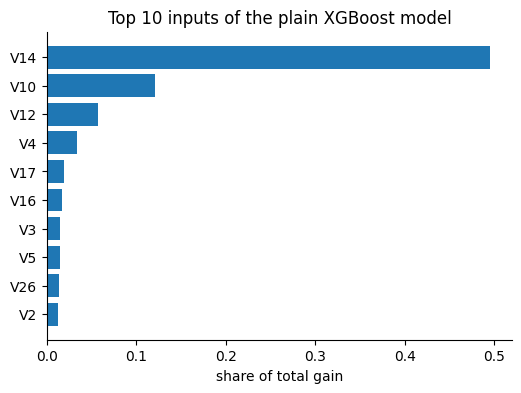

In [57]:
importance = pd.Series(xgb_plain.feature_importances_, index=FEATURES)
top10 = importance.sort_values(ascending=True).tail(10)
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top10.index, top10.values)
ax.set_xlabel("share of total gain")
ax.set_title("Top 10 inputs of the plain XGBoost model")
plt.show()

One anonymous input, V14, provides about half of the total gain, and
five inputs provide three quarters. `Amount` ranks only 15th for
*predicting* fraud, but it is central to the *decision*.

## 14. Save the model and what notebook 02 needs

1. **`model.json`**: the plain XGBoost model in XGBoost's own format. It
   loads without pickle, which is safer and survives library upgrades.
2. **A drift reference**: how the training data was spread across bins,
   for the monitoring notebook. We watch the model's score, `Amount`,
   `hour_of_day` and the five most important inputs.
3. **`model_card.json`**: inputs, review cost, split hours, test results
   and the drift reference, all in one file.

In [58]:
ARTIFACTS.mkdir(exist_ok=True)
xgb_plain.save_model(ARTIFACTS / "model.json")
print("Saved", (ARTIFACTS / "model.json").name)

Saved model.json


### 14.1 How the drift reference is built

The monitoring notebook asks, for each watched column: *is today's
data spread the way the training data was?* To answer that later, we
store the training spread now. `build_reference` does it. The same code is saved in
`src/monitoring.py`, where notebook 02 uses it, so both notebooks
measure the same way. It has three parts, each a small function:

1. `make_edges`: cut a column into 10 groups that each hold about 10%
   of the training values, and return the cut points.
2. `share_per_bin`: count what share of values land in each group.
3. `build_reference`: repeat 1 and 2 for every watched column and keep
   the results.

First the two building blocks.

In [59]:
def make_edges(reference_values, n_bins=10):
    """Bin edges at the training data's deciles, open at both ends."""
    cut_points = np.linspace(0, 1, n_bins + 1)[1:-1]
    inner = np.unique(np.quantile(reference_values, cut_points))
    edges = np.concatenate([[-np.inf], inner, [np.inf]])
    return edges

def share_per_bin(values, edges):
    """Fraction of values that fall in each bin."""
    counts, _ = np.histogram(values, bins=edges)
    shares = counts / max(len(values), 1)
    return np.clip(shares, 0.0001, None)

**`make_edges`.** `np.linspace` gives the fractions 0.1, 0.2 up to 0.9.
`np.quantile` turns each fraction into the actual value below which
that share of the column lies. `np.unique` drops repeated cut points,
which happens when many payments share one amount. The first and last
edges are minus and plus infinity, so any future value lands in some
group.

**`share_per_bin`.** `np.histogram` counts the values in each group,
and dividing by the number of values gives shares. `np.clip` keeps any
share from being exactly zero, because the drift score takes a
logarithm later.

Now both on a real column, `Amount` in the training part.

In [60]:
amount_edges = make_edges(train["Amount"].values)
amount_share = share_per_bin(train["Amount"].values, amount_edges)
bins = pd.DataFrame({"from": amount_edges[:-1],
                     "to": amount_edges[1:],
                     "share": amount_share})
bins.round(3)


,from,to,share
0,-inf,1.00,0.058
1,1.00,3.30,0.142
2,3.30,8.50,0.100
3,8.50,12.98,0.100
4,12.98,21.40,0.100
5,21.40,36.29,0.100
6,36.29,59.15,0.100
7,59.15,99.99,0.099
8,99.99,200.00,0.100
9,200.00,inf,0.101


Nine cut points give ten groups, from under €1 to over €200. Most
groups hold 10% of the training payments, as intended. The first two do
not (5.8% and 14.2%): many payments are exactly €1.00, and a cut point
at €1.00 cannot split identical values, so they all land together in the
second group. That is fine. What matters later is that old and new data
are sorted into the same groups.

**`build_reference`.** It loops over the watched columns, calls those
two functions on each, and stores the cut points and shares in a
dictionary. It keeps only the inner cut points, because the file we
save to (JSON) cannot hold infinity. The drift code adds the two
infinite ends back.

In [61]:
def build_reference(df, columns):
    """Store edges and shares for each column, taken from training data."""
    reference = {}
    for col in columns:
        edges = make_edges(df[col].values)
        shares = share_per_bin(df[col].values, edges)
        # Store only the inner edges: JSON has no infinity.
        reference[col] = {"inner_edges": edges[1:-1].tolist(),
                          "share": shares.tolist()}
    return reference

Now we use it on the columns we want to watch.

For the drift reference we need the model's score on each training row, so
we make `train_ref`: the training part plus a `score` column.

In [62]:
train_ref = train.copy()
train_ref["score"] = xgb_plain.predict_proba(X_train)[:, 1]

monitor_cols = ["score", "Amount", "hour_of_day"]
ranked = importance.sort_values(ascending=False).index
for col in ranked[:5]:
    if col not in monitor_cols:
        monitor_cols.append(col)
reference = build_reference(train_ref, monitor_cols)
print("Columns to watch for drift:", monitor_cols)
train_ref[monitor_cols].head()

Columns to watch for drift: ['score', 'Amount', 'hour_of_day', 'V14', 'V10', 'V12', 'V4', 'V17']


,score,Amount,hour_of_day,V14,V10,V12,V4,V17
0,0.000075,149.62,0,-0.311169,0.090794,-0.617801,1.378155,0.207971
1,0.000008,2.69,0,-0.143772,-0.166974,1.065235,0.448154,-0.114805
2,0.000081,378.66,0,-0.165946,0.207643,0.066084,0.379780,1.109969
3,0.000001,123.50,0,-0.287924,-0.054952,0.178228,-0.863291,-0.684093
4,0.000005,69.99,0,-1.119670,0.753074,0.538196,0.403034,-0.237033


What `build_reference` stored for one column, `Amount`: the cut points
and the share of training payments in each group. These are the numbers
the drift check compares against later.

In [63]:
stored = reference["Amount"]
print("Stored keys:", list(stored))
print("Inner edges:", np.round(stored["inner_edges"], 2))
print("Shares:     ", np.round(stored["share"], 3))


Stored keys: ['inner_edges', 'share']
Inner edges: [  1.     3.3    8.5   12.98  21.4   36.29  59.15  99.99 200.  ]
Shares:      [0.058 0.142 0.1   0.1   0.1   0.1   0.1   0.099 0.1   0.101]


In [64]:
card = {
    "model_version": "xgb-plain-v1",
    "features": FEATURES,
    "review_cost_eur": REVIEW_COST_EUR,
    "train_end_hour": TRAIN_END_HOUR,
    "valid_end_hour": VALID_END_HOUR,
    "test_pr_auc": round(float(average_precision_score(y_test, p_test)), 4),
    "test_cost_eur": test_table["total_cost_eur"].to_dict(),
    "drift_reference": reference,
}
with open(ARTIFACTS / "model_card.json", "w") as f:
    json.dump(card, f, indent=2)
print("Saved model_card.json with keys:", list(card))

Saved model_card.json with keys: ['model_version', 'features', 'review_cost_eur', 'train_end_hour', 'valid_end_hour', 'test_pr_auc', 'test_cost_eur', 'drift_reference']


## 15. Recap

- **Data:** 283,726 real payments after removing 1,081 duplicates; 473
  frauds.
- **Validation design:** trained on hours 0 to 32, rule chosen on 32 to 40,
  judged once on 40 to 48.
- **Model:** plain XGBoost, test PR-AUC 0.80 (logistic baseline 0.71).
  Its top 100 payments hold 60 frauds (precision@100 of 0.60, out of a
  possible 0.76). Class weights and SMOTE did not rank better, and they
  distort the probabilities. A light tuning check (12 settings, scored
  in time order inside training) found none clearly better than the
  defaults.
- **Decision:** review when fraud probability × amount > €5. On the test
  period this cost €2,807, against €4,006 for a 0.5 threshold and €8,395
  for no model. The gain over 0.5 is likely but not certain (cheaper in
  92% of bootstrap re-deals).
- **Saved:** `model.json` and `model_card.json` (inputs, review cost,
  split hours, test results and the drift reference), which notebook 02
  reads.

**Next:** `02_drift_monitoring.ipynb` checks whether the inputs and scores
stay stable over the two days, which is what we would watch in production
while waiting weeks for chargeback labels.